In [81]:
from typing import List, Callable
from scipy.optimize import approx_fprime
from scipy.differentiate import hessian

import matplotlib.pyplot as plt
import numpy as np
from timeit import timeit

import sys
sys.path.insert(0, "/Users/Даниил/OneDrive/Desktop/МРОЗ - 7 вариант")
from visualisation import plot_trajectory_3d_plotly, plot_trajectory
from test_functions import rosenbroke, himmelbau, rostrigin, izom


In [82]:
Vector = List[float]

In [83]:
def function_5(x: Vector): return (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2 # из (0, 3) прийти в (0, 1) из (3, 0) в (1, 0)

def function_1(x:Vector): return 2 * x[0]**2 + x[0]*x[1] + x[1]**2 # из (0.5 , 1) в какой-то ответ хз не найден

In [84]:
def markvardt(x0: Vector, f: Callable, eps_1 = 1e-8, max_iter = 10000):
    x = np.array(x0, dtype=float)
    n = x.size
    H = np.eye(n)
    k = 0
    mu_k = 0
    traj = [x.copy()]

    grad = lambda v: approx_fprime(v, f, eps_1)
    g = grad(x)

    while np.linalg.norm(g) > eps_1 and k < max_iter:
        # g = grad(x)
        

        for _ in range(60):
            H = hessian(f, x).ddf
            H = np.linalg.inv(H + mu_k * np.eye(n))
            
            try: d_k = -H @ g
            except:
                mu_k *= 2.0
                continue
        # d_k = np.linalg.solve(Hm + mu * np.eye(n), -g)

            x_new = x + d_k

            if f(x_new) < f(x):
                x = x_new
                mu_k = max(mu_k / 2.0, 1e-12)
                traj.append(x.copy())
                break
            else: mu_k = min(mu_k * 2.0, 1e12)
        else: mu_k *= 2.0

        if np.linalg.norm(d_k) < eps_1:  break
        g = grad(x)
        k +=1

    return x, f(x), k, traj


In [85]:
def newton(x0: Vector, f:Callable, eps_1=1e-8, eps_2=1e-10, max_iter=100):
    x = np.array(x0, dtype=float)
    n = x.size
    H = np.eye(n)
    k = 0
    traj = [x.copy()]

    grad = lambda v: approx_fprime(v, f)
    g = grad(x)
    f_current = f(x)

    previos = True
    while np.linalg.norm(g) > eps_1 and k < max_iter:
        H = hessian(f, x, maxiter=12, order=10, initial_step=0.4).ddf
        H_inv = np.linalg.inv(H)

        if np.linalg.norm(H_inv) > eps_2:
            d_k = -H_inv @ g

            t_k = 1.0
            x_new = x + t_k*d_k

        else:
            d_k = -g

            t_k = 0.5
            while f(x + t_k*d_k) >= f_current and t_k >= eps_2:
                t_k *= 0.5
                
            x_new = x + t_k*d_k
            traj.append(x_new)


        f_new = f(x_new)

        if np.linalg.norm(x_new - x) < eps_2 and abs(f_new - f(x)) < eps_2:
            if previos:
                return x, f(x_new), k+1, np.array(traj)
            else: previos = False

        x = x_new
        g = grad(x)
        f_current = f_new

        traj.append(x.copy())
        k+=1

    return x, f_current, k, traj

In [86]:
%timeit newton([0, 3], function_5, eps_1=1e-6, eps_2=1e-8, max_iter=100)

54 ms ± 8.67 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [87]:
x_newton, f_newton, k_newton, traj_newton = newton([0, 3], function_5, eps_1=1e-6, eps_2=1e-8, max_iter=100)
print(f"Итог: x* = {x_newton}, f* = {f_newton:.3e}, k = {k_newton}\n")

Итог: x* = [-1.16622308e-07  1.00000004e+00], f* = 1.242e-14, k = 7



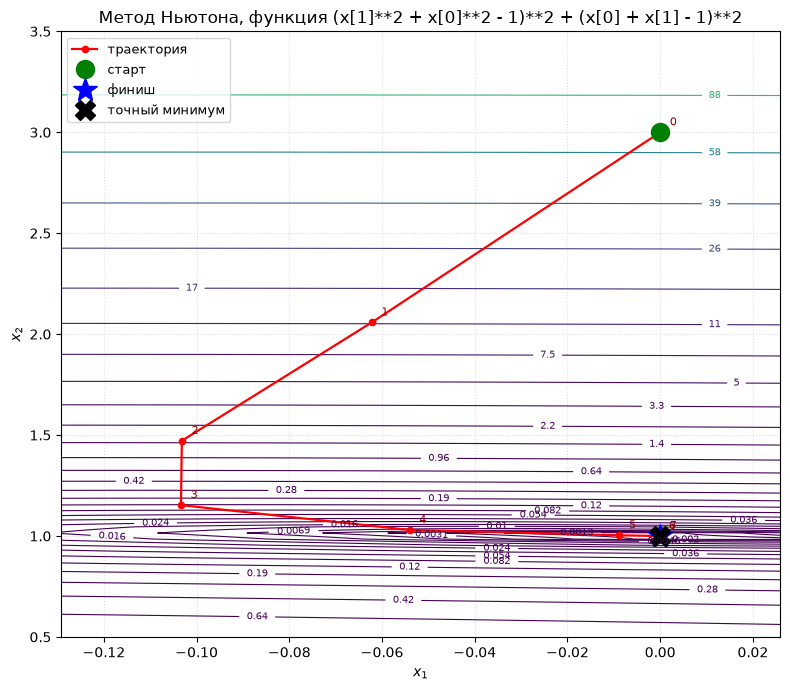

In [88]:
plot_trajectory(function_5, traj_newton, title="Метод Ньютона, функция (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2", exact=(0, 1))

In [89]:
plot_trajectory_3d_plotly(function_5, traj_newton, title="Метод Ньютона, функция (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2", exact=(0, 1))

In [90]:
%timeit newton([3, 0], function_5, eps_1=1e-6, eps_2=1e-8, max_iter=100)

The slowest run took 6.02 times longer than the fastest. This could mean that an intermediate result is being cached.
80.5 ms ± 71.8 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [91]:
x_newton, f_newton, k_newton, traj_newton = newton([3, 0], function_5, eps_1=1e-6, eps_2=1e-8, max_iter=100)
print(f"Итог: x* = {x_newton}, f* = {f_newton:.3e}, k = {k_newton}\n")

Итог: x* = [ 1.00000004e+00 -1.16622185e-07], f* = 1.242e-14, k = 7



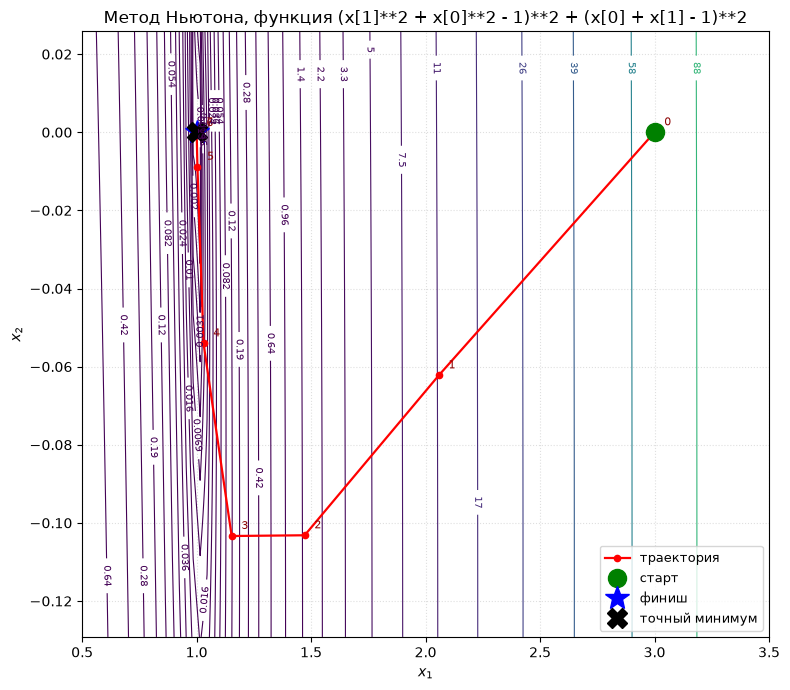

In [92]:
plot_trajectory(function_5, traj_newton, title="Метод Ньютона, функция (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2", exact=(1, 0))

In [93]:
plot_trajectory_3d_plotly(function_5, traj_newton, title="Метод Ньютона, функция (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2", exact=(1, 0))

In [94]:
%timeit newton([0.5, 1], function_1, eps_1=1e-6, eps_2=1e-8, max_iter=100)

5.28 ms ± 1.12 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [95]:
x_newton, f_newton, k_newton, traj_newton = newton([0.5, 1], function_1, eps_1=1e-6, eps_2=1e-8, max_iter=100)
print(f"Итог: x* = {x_newton}, f* = {f_newton:.3e}, k = {k_newton}\n")

Итог: x* = [-8.51385873e-09  4.25764868e-09], f* = 1.269e-16, k = 1



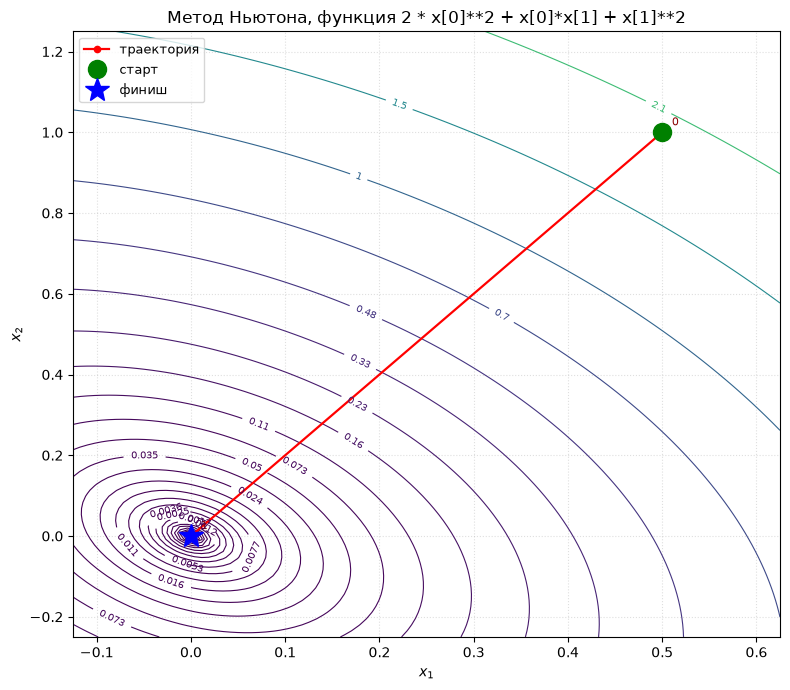

In [96]:
plot_trajectory(function_1, traj_newton, title="Метод Ньютона, функция 2 * x[0]**2 + x[0]*x[1] + x[1]**2")

In [97]:
plot_trajectory_3d_plotly(function_1, traj_newton, title="Метод Ньютона, функция 2 * x[0]**2 + x[0]*x[1] + x[1]**2")

In [98]:
%timeit markvardt([0, 3], function_5)

35.8 ms ± 1.74 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [99]:
x_mark, f_mark, k_mark, traj_mark = markvardt([0, 3], function_5)
print(f"Итог: x* = {x_mark}, f* = {f_mark:.3e}, k = {k_mark}\n")

Итог: x* = [-3.82652435e-14  9.99999995e-01], f* = 1.250e-16, k = 8



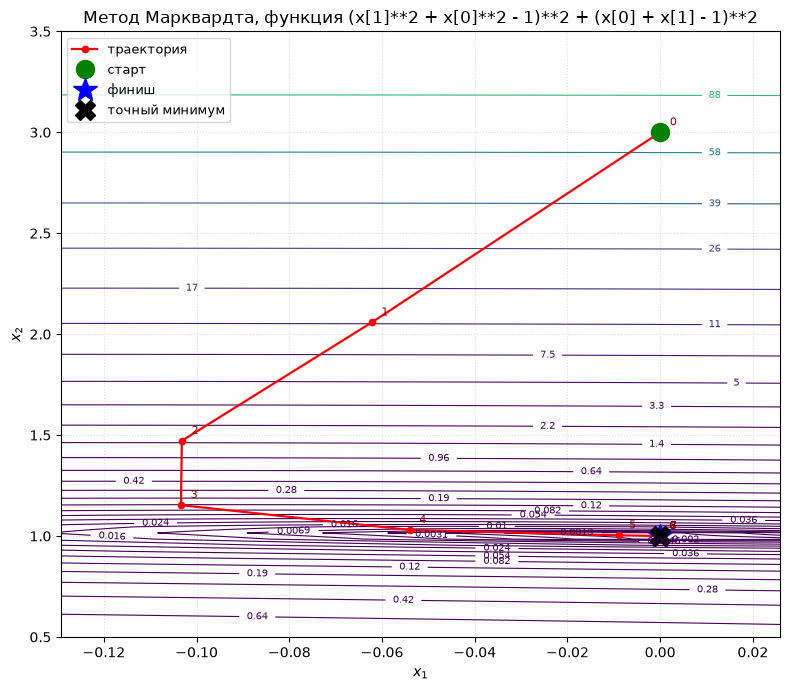

In [100]:
plot_trajectory(f=function_5, traj=traj_mark, title="Метод Марквардта, функция (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2", exact=(0, 1))

In [101]:
plot_trajectory_3d_plotly(f=function_5, traj=traj_mark, title="Метод Марквардта, функция (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2", exact=(0, 1))

In [102]:
%timeit markvardt([3, 0], function_5)

44.2 ms ± 10.5 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [103]:
x_mark, f_mark, k_mark, traj_mark = markvardt([3, 0], function_5)
print(f"Итог: x* = {x_mark}, f* = {f_mark:.3e}, k = {k_mark}\n")

Итог: x* = [ 9.99999995e-01 -3.92006827e-14], f* = 1.250e-16, k = 8



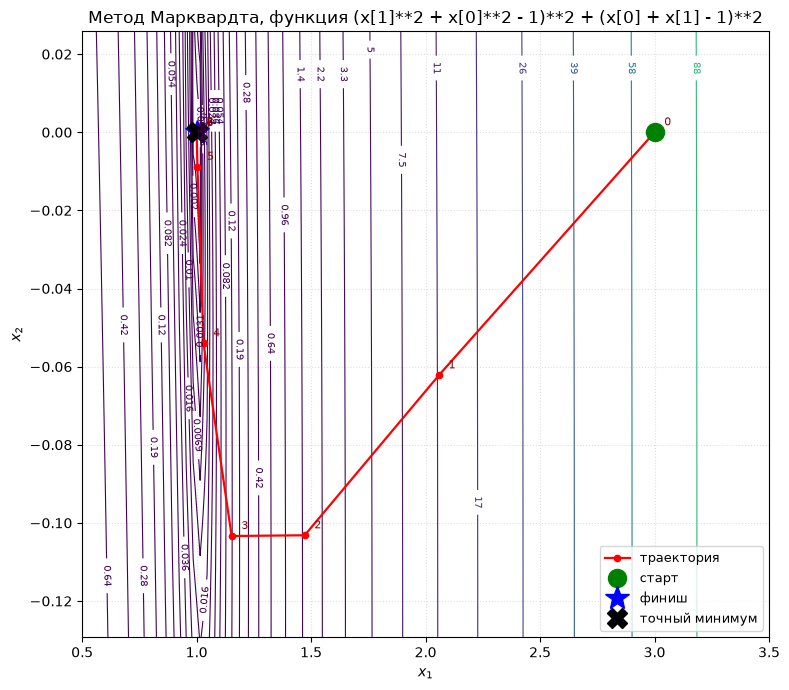

In [104]:
plot_trajectory(f=function_5, traj=traj_mark, title="Метод Марквардта, функция (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2", exact=(1, 0))

In [105]:
plot_trajectory_3d_plotly(f=function_5, traj=traj_mark, title="Метод Марквардта, функция (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2", exact=(1, 0))

In [106]:
%timeit markvardt([0.5, 1], function_1)

578 ms ± 62.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [107]:
x_mark, f_mark, k_mark, traj_mark = markvardt([0.5, 1], function_1)

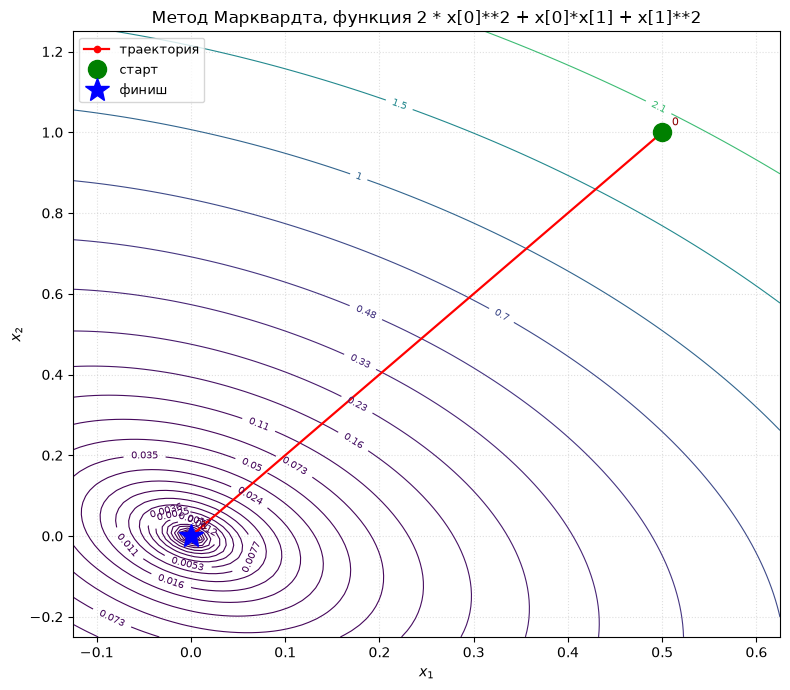

In [108]:
plot_trajectory(f=function_1, traj=traj_mark, title="Метод Марквардта, функция 2 * x[0]**2 + x[0]*x[1] + x[1]**2")

In [109]:
plot_trajectory_3d_plotly(f=function_1, traj=traj_mark, title="Метод Марквардта, функция 2 * x[0]**2 + x[0]*x[1] + x[1]**2")